# LAB 09 — Bias, Variance and Imbalanced Data
## Overfitting, ROC/AUC, Resampling, SMOTE and Noisy Data on Real Medical Data

## Student Information
- **Name:* Muhammad Sufian*
- **Student ID:* 023-24-0007*
- **Section:* B*
- **GitHub:**
- **Kaggle:* https://www.kaggle.com/mohammadsufian3232*
- **Dataset:** Stroke Prediction Dataset (Kaggle)
- **Dataset Source:** https://www.kaggle.com/datasets/fedesoriano/stroke-prediction-dataset

### Before You Start
- You already know the models, scaling, splitting and cross-validation from Labs 3-8. This lab does not re-teach them.
- Every task ends with a question about **your own results**. A table or plot without a written interpretation earns no marks.
- Use `SEED = 42` everywhere. **Golden rule:** anything that learns from data (scaler, imputer, resampler, threshold) is learned from the **training data only**.
- Install once if needed: `pip install imbalanced-learn`


---

## Part 0 — Setup and the Data
A hospital wants to flag patients at risk of stroke from routine information. Target: `stroke` (1 = had a stroke, 0 = did not).

**What to do:**
1. Import everything you need (including `imblearn`) and set `SEED = 42`.
2. Load the CSV. Report the shape, the columns with missing values, the value counts of `gender`, and the number of patients with `stroke = 1` and `stroke = 0` (count and %).
3. Clean: remove the identifier column; remove any `gender` category with too few rows to learn or test; apply categorical encoding (`pd.get_dummies`) to the text columns.
4. Split 80/20 with `stratify=y`, `random_state=SEED`. Fill missing numeric values with a median learned from the **train** set only. Make a scaled copy (`StandardScaler` fitted on train) for Logistic Regression.
5. Report the number of stroke cases in the train and in the test set.

In [1]:
# YOUR CODE HERE
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import (train_test_split, StratifiedKFold, cross_val_score,
                                     cross_val_predict, learning_curve)
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, average_precision_score, confusion_matrix,
                             roc_curve, precision_recall_curve)
from imblearn.over_sampling import SMOTE, RandomOverSampler
from imblearn.under_sampling import RandomUnderSampler

SEED = 42

df = pd.read_csv("healthcare-dataset-stroke-data.csv")
print("Shape:", df.shape)
print("\nMissing values per column (only those with missing):")
miss = df.isna().sum()
print(miss[miss > 0])
print("\nGender value counts:")
print(df["gender"].value_counts())
vc = df["stroke"].value_counts()
print("\nstroke = 0: %d (%.2f%%)" % (vc[0], 100 * vc[0] / len(df)))
print("stroke = 1: %d (%.2f%%)" % (vc[1], 100 * vc[1] / len(df)))


Shape: (5110, 12)

Missing values per column (only those with missing):
bmi    201
dtype: int64

Gender value counts:
gender
Female    2994
Male      2115
Other        1
Name: count, dtype: int64

stroke = 0: 4861 (95.13%)
stroke = 1: 249 (4.87%)


In [2]:
# YOUR CODE HERE
# Clean: drop id, drop the single "Other" gender row, one-hot encode text columns
df = df.drop(columns="id")
df = df[df["gender"] != "Other"].reset_index(drop=True)
df = pd.get_dummies(df, drop_first=True, dtype=int)

X = df.drop(columns="stroke")
y = df["stroke"]

# 80/20 stratified split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=SEED)

# Median learned from TRAIN only, applied to both
med = X_train.median()
X_train = X_train.fillna(med)
X_test = X_test.fillna(med)

# Scaled copy for Logistic Regression (scaler fitted on train only)
scaler = StandardScaler().fit(X_train)
Xs_train = pd.DataFrame(scaler.transform(X_train), columns=X.columns, index=X_train.index)
Xs_test = pd.DataFrame(scaler.transform(X_test), columns=X.columns, index=X_test.index)

print("Train:", X_train.shape, " Test:", X_test.shape)
print("Stroke cases  train: %d (%.2f%%)   test: %d (%.2f%%)" %
      (y_train.sum(), 100 * y_train.mean(), y_test.sum(), 100 * y_test.mean()))

Train: (4087, 15)  Test: (1022, 15)
Stroke cases  train: 199 (4.87%)   test: 50 (4.89%)


**Question 0.1:** In 2–3 lines: how imbalanced is the data? Why did we use `stratify=y`, and what could go wrong with only a few stroke cases in the test set?

**Your answer:**

Only 4.87% of patients (249 of 5,109) had a stroke, so the data is strongly imbalanced. `stratify=y` keeps the same stroke rate in train (199 cases) and test (50 cases). Without it the test set could get very few strokes, and the metrics would be unreliable.


---

## Part 1 — The Accuracy Trap
**Objective:** show that a model can have excellent accuracy and still be useless.
1. Build a baseline that always predicts the majority class (`DummyClassifier(strategy='most_frequent')`). Report accuracy.
2. Train a default Logistic Regression on the scaled training data. Report Accuracy, Precision, Recall, F1, ROC AUC and PR AUC (average precision) on the test set, and print the confusion matrix.
3. Write a helper function that takes a model and train/test data and returns these six metrics (you will reuse it all lab).

In [3]:
# YOUR CODE HERE
def evaluate(model, Xtr, ytr, Xte, yte, fit=True):
    """Return Accuracy, Precision, Recall, F1, ROC AUC, PR AUC on the test set."""
    if fit:
        model.fit(Xtr, ytr)
    pred = model.predict(Xte)
    proba = model.predict_proba(Xte)[:, 1]
    return {"Accuracy": accuracy_score(yte, pred),
            "Precision": precision_score(yte, pred, zero_division=0),
            "Recall": recall_score(yte, pred),
            "F1": f1_score(yte, pred, zero_division=0),
            "ROC AUC": roc_auc_score(yte, proba),
            "PR AUC": average_precision_score(yte, proba)}

dummy = DummyClassifier(strategy="most_frequent").fit(Xs_train, y_train)
print("Majority-class baseline accuracy: %.4f" % accuracy_score(y_test, dummy.predict(Xs_test)))


Majority-class baseline accuracy: 0.9511


In [4]:
# YOUR CODE HERE
lr = LogisticRegression(max_iter=1000, random_state=SEED)
res_lr = evaluate(lr, Xs_train, y_train, Xs_test, y_test)
print(pd.Series(res_lr).round(4).to_string())
print("\nConfusion matrix (rows = true 0/1, columns = predicted 0/1):")
print(confusion_matrix(y_test, lr.predict(Xs_test)))

Accuracy     0.9521
Precision    1.0000
Recall       0.0200
F1           0.0392
ROC AUC      0.8394
PR AUC       0.2692

Confusion matrix (rows = true 0/1, columns = predicted 0/1):
[[972   0]
 [ 49   1]]


**Question 1.1:** Compare the accuracy of the baseline and of Logistic Regression. What do you conclude?

**Question 1.2:** Look at the confusion matrix and the recall. In the hospital's situation, what does a false negative mean, and which numbers should we trust instead of accuracy?

**Your answer:**

**1.1:** The baseline accuracy is 0.9511 and Logistic Regression is 0.9521, almost the same. Accuracy looks high only because 95% of patients are healthy, so it tells us nothing useful here.

**1.2:** A false negative is a stroke patient we told "no stroke". The confusion matrix shows 49 missed strokes and only 1 caught (recall 0.02). We should trust recall, F1, ROC AUC and PR AUC instead of accuracy.


---

## Part 2 — Underfitting, Overfitting, Bias and Variance
Use **ROC AUC** (not accuracy) as the score from now on.

### Task 2.1 — Validation curve
For `max_depth` = 1, 2, …, 15 and `None`, record the train ROC AUC and the 5-fold stratified CV ROC AUC (train data only). Plot both curves on one chart (labels, title, legend) and report the best depth by CV AUC.

max_depth  Train AUC  CV AUC
        1     0.7171  0.7317
        2     0.8208  0.8168
        3     0.8375  0.8161
        4     0.8580  0.8180
        5     0.8758  0.7921
        6     0.9026  0.7585
        7     0.9276  0.7385
        8     0.9494  0.7138
        9     0.9678  0.6812
       10     0.9808  0.6414
       11     0.9910  0.6108
       12     0.9959  0.6126
       13     0.9985  0.5955
       14     0.9996  0.5889
       15     0.9999  0.5779
     None     1.0000  0.5644

Best depth by CV AUC: 4  (CV AUC 0.8180)


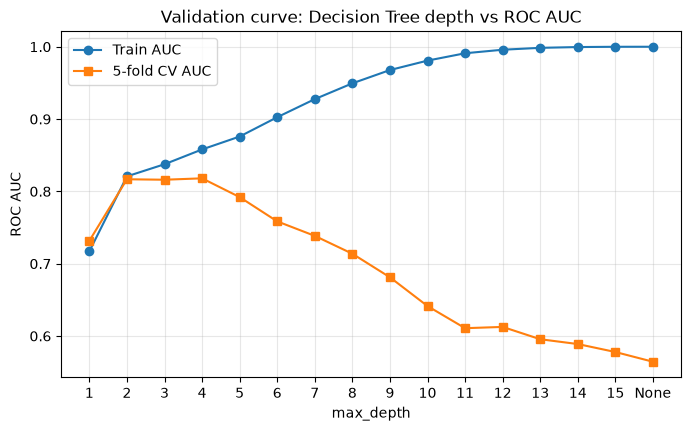

In [5]:
# YOUR CODE HERE
depths = list(range(1, 16)) + [None]
skf = StratifiedKFold(5, shuffle=True, random_state=SEED)
rows = []
for d in depths:
    tree = DecisionTreeClassifier(max_depth=d, random_state=SEED)
    tr_auc = roc_auc_score(y_train, tree.fit(X_train, y_train).predict_proba(X_train)[:, 1])
    cv_auc = cross_val_score(tree, X_train, y_train, cv=skf, scoring="roc_auc").mean()
    rows.append({"max_depth": "None" if d is None else d, "Train AUC": tr_auc, "CV AUC": cv_auc})
vc_df = pd.DataFrame(rows)
print(vc_df.round(4).to_string(index=False))

best = vc_df.loc[vc_df["CV AUC"].idxmax()]
print("\nBest depth by CV AUC:", best["max_depth"], " (CV AUC %.4f)" % best["CV AUC"])

xs = range(len(vc_df))
plt.figure(figsize=(8, 4.5))
plt.plot(xs, vc_df["Train AUC"], "o-", label="Train AUC")
plt.plot(xs, vc_df["CV AUC"], "s-", label="5-fold CV AUC")
plt.xticks(xs, vc_df["max_depth"])
plt.xlabel("max_depth"); plt.ylabel("ROC AUC")
plt.title("Validation curve: Decision Tree depth vs ROC AUC")
plt.legend(); plt.grid(alpha=0.3); plt.show()

### Task 2.2 — Learning curves
Use `learning_curve` (`scoring='roc_auc'`, train sizes 20%→100%) for a tree with `max_depth=1` and a tree with `max_depth=None`. Plot train and CV AUC against the number of training rows, side by side.

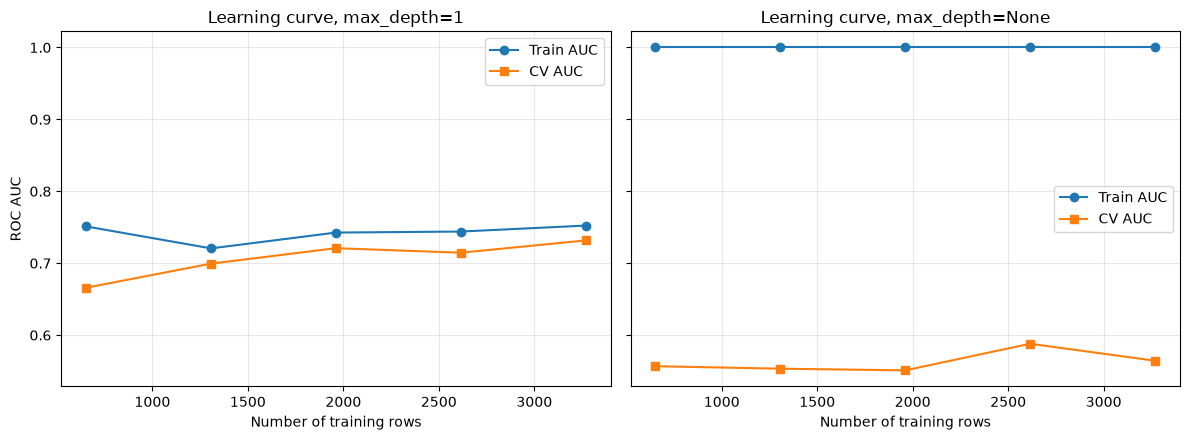

In [6]:
# YOUR CODE HERE
sizes = np.linspace(0.2, 1.0, 5)
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), sharey=True)
for ax, d in zip(axes, [1, None]):
    tree = DecisionTreeClassifier(max_depth=d, random_state=SEED)
    n, tr, cv = learning_curve(tree, X_train, y_train, train_sizes=sizes, cv=skf,
                               scoring="roc_auc", random_state=SEED, shuffle=True)
    ax.plot(n, tr.mean(axis=1), "o-", label="Train AUC")
    ax.plot(n, cv.mean(axis=1), "s-", label="CV AUC")
    ax.set_title("Learning curve, max_depth=%s" % d)
    ax.set_xlabel("Number of training rows"); ax.grid(alpha=0.3); ax.legend()
axes[0].set_ylabel("ROC AUC")
plt.tight_layout(); plt.show()


### Task 2.3 — Measure variance directly
Variance = if the training data changes a little, how much do the predictions change?
1. For `max_depth` = 1, 3 and `None`: draw **40 bootstrap samples** of the train rows (with replacement, same size), fit a tree on each, and collect each tree's predicted stroke probability for every test patient.
2. For every test patient compute the variance of its 40 probabilities, then average over patients. Also report the mean test ROC AUC of the 40 trees and the ROC AUC of the **averaged** prediction.
3. Show the three depths in one table.

*Hints:* `rng.choice(len(X_train), len(X_train), replace=True)` and `X_train.iloc[idx]`; collect an array of shape (40, n_test); `probs.var(axis=0)`.

In [7]:
# YOUR CODE HERE
rng = np.random.default_rng(SEED)
out = []
for d in [1, 3, None]:
    probs = np.zeros((40, len(X_test)))
    for b in range(40):
        idx = rng.choice(len(X_train), len(X_train), replace=True)
        t = DecisionTreeClassifier(max_depth=d, random_state=SEED)
        t.fit(X_train.iloc[idx], y_train.iloc[idx])
        probs[b] = t.predict_proba(X_test)[:, 1]
    out.append({"max_depth": "None" if d is None else d,
                "Mean variance of prediction": probs.var(axis=0).mean(),
                "Mean AUC of single trees": np.mean([roc_auc_score(y_test, p) for p in probs]),
                "AUC of averaged prediction": roc_auc_score(y_test, probs.mean(axis=0))})
print(pd.DataFrame(out).round(5).to_string(index=False))

max_depth  Mean variance of prediction  Mean AUC of single trees  AUC of averaged prediction
        1                      0.00068                   0.76234                     0.81317
        3                      0.00167                   0.79644                     0.83429
     None                      0.04197                   0.55525                     0.75659


**Question 2.1:** From the validation curve: which depths underfit, which overfit, and which depth would you choose? Quote train and CV AUC for one depth in each zone.

**Question 2.2:** From the learning curves: how can you tell high bias from high variance? Will adding more training rows fix either one?

**Question 2.3:** From the variance table: how does variance change with depth? What happens to the AUC of the averaged prediction compared with the single trees? Link this to what Random Forest does (Lab 4).

**Question 2.4:** In your own words: what is the bias-variance trade-off, and where do depth 1, depth 3 and depth None sit?

**Your answer:**

**2.1:** Depth 1 underfits (train 0.717, CV 0.732). Depths 2 to 4 are good, and depth 4 has the best CV AUC (train 0.858, CV 0.818), so I choose depth 4. Deep trees overfit: depth None has train 1.000 but CV 0.564.

**2.2:** Depth 1: train and CV curves are both low and close together, which means high bias. Depth None: train AUC stays at 1.0 but CV AUC is about 0.56, a big gap, which means high variance. More rows do not fix high bias, and they barely helped the deep tree here (CV 0.557 to 0.564).

**2.3:** Variance grows with depth: 0.00068 (depth 1), 0.00167 (depth 3), 0.04197 (None). The averaged prediction has a higher AUC than the single trees (for example 0.757 vs 0.555 for depth None). Random Forest does exactly this: it averages many trees to reduce variance.

**2.4:** The bias-variance trade-off: a simple model has high bias and low variance, a complex model has low bias and high variance, and we want a balance. Depth 1 is high bias (underfit), depth 3 is balanced, depth None is high variance (overfit).




---

## Part 3 — ROC, AUC, Precision-Recall and Thresholds
### Task 3.1 — Compare models with curves
1. Train Logistic Regression (scaled), Decision Tree (`max_depth=3`) and Random Forest (200 trees, `min_samples_leaf=5`, `random_state=SEED`) on the original training data.
2. Draw the ROC curves of the three models on one chart (AUC in the legend, random-guessing diagonal).
3. Draw the Precision-Recall curves on a second chart. Add a horizontal **no-skill line** (the stroke rate) and put the average precision in the legend.

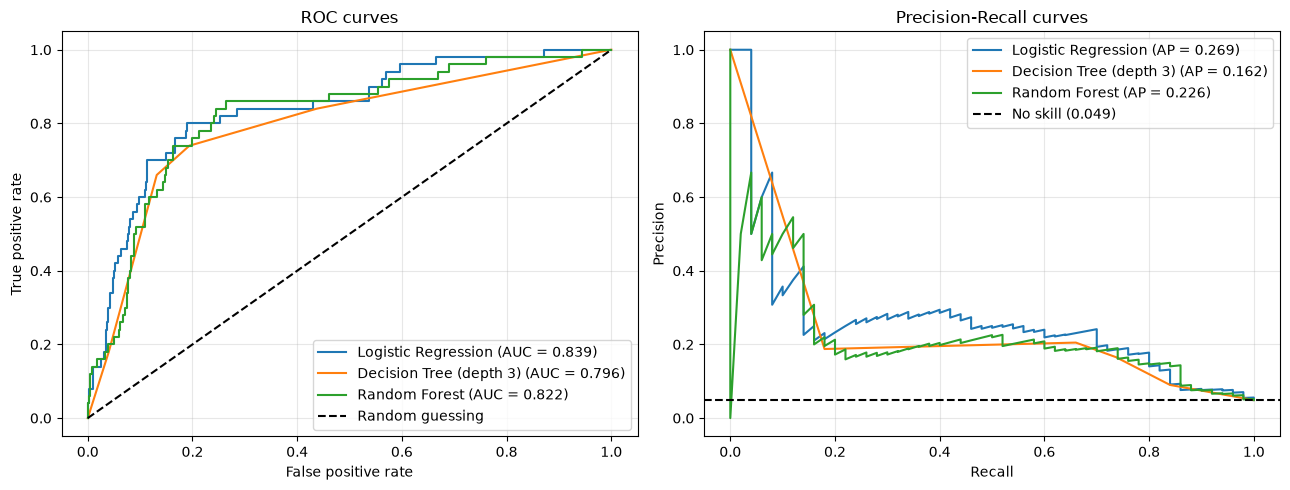

In [8]:
# YOUR CODE HERE
lr3 = LogisticRegression(max_iter=1000, random_state=SEED).fit(Xs_train, y_train)
dt3 = DecisionTreeClassifier(max_depth=3, random_state=SEED).fit(X_train, y_train)
rf = RandomForestClassifier(n_estimators=200, min_samples_leaf=5, random_state=SEED, n_jobs=-1).fit(X_train, y_train)
models = {"Logistic Regression": (lr3, Xs_test), "Decision Tree (depth 3)": (dt3, X_test),
          "Random Forest": (rf, X_test)}

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for name, (m, Xt) in models.items():
    p = m.predict_proba(Xt)[:, 1]
    fpr, tpr, _ = roc_curve(y_test, p)
    axes[0].plot(fpr, tpr, label="%s (AUC = %.3f)" % (name, roc_auc_score(y_test, p)))
    pr, rc, _ = precision_recall_curve(y_test, p)
    axes[1].plot(rc, pr, label="%s (AP = %.3f)" % (name, average_precision_score(y_test, p)))
axes[0].plot([0, 1], [0, 1], "k--", label="Random guessing")
axes[0].set_xlabel("False positive rate"); axes[0].set_ylabel("True positive rate")
axes[0].set_title("ROC curves"); axes[0].legend(loc="lower right")
axes[1].axhline(y_test.mean(), color="k", ls="--", label="No skill (%.3f)" % y_test.mean())
axes[1].set_xlabel("Recall"); axes[1].set_ylabel("Precision")
axes[1].set_title("Precision-Recall curves"); axes[1].legend()
for a in axes: a.grid(alpha=0.3)
plt.tight_layout(); plt.show()


### Task 3.2 — Choose a decision threshold
The hospital wants to catch **at least 80%** of strokes.
1. Using **only the training data**, get out-of-fold probabilities for Logistic Regression (`cross_val_predict(..., method='predict_proba')`), then find the highest threshold that gives recall ≥ 0.80 on them.
2. Apply that threshold to the **test** probabilities. Report test recall, precision, the confusion matrix, how many patients are flagged and how many are false alarms.

In [9]:
# YOUR CODE HERE
pipe_lr = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000, random_state=SEED))
oof = cross_val_predict(pipe_lr, X_train, y_train, cv=skf, method="predict_proba")[:, 1]

prec, rec, thr = precision_recall_curve(y_train, oof)
ok = thr[rec[:-1] >= 0.80]
threshold = ok.max()                      # highest threshold that still gives recall >= 0.80
print("Chosen threshold (from train out-of-fold): %.4f" % threshold)

# Apply to the test set
p_test = lr3.predict_proba(Xs_test)[:, 1]
pred_t = (p_test >= threshold).astype(int)
cm = confusion_matrix(y_test, pred_t)
tn, fp, fn, tp = cm.ravel()
print("\nTEST  recall: %.3f   precision: %.3f" % (recall_score(y_test, pred_t), precision_score(y_test, pred_t)))
print("Confusion matrix:\n", cm)
print("Patients flagged: %d of %d   (true strokes caught: %d, false alarms: %d, missed strokes: %d)" %
      (pred_t.sum(), len(y_test), tp, fp, fn))

Chosen threshold (from train out-of-fold): 0.0509

TEST  recall: 0.820   precision: 0.135
Confusion matrix:
 [[710 262]
 [  9  41]]
Patients flagged: 303 of 1022   (true strokes caught: 41, false alarms: 262, missed strokes: 9)


**Question 3.1:** In Part 1 the recall was very low, yet the ROC AUC of Logistic Regression is far above 0.5. How can both be true? What does AUC measure, and what does the 0.5 threshold have to do with it?

**Question 3.2:** Which curve is more informative for this data — ROC or Precision-Recall — and why? Use the no-skill line in your answer.

**Question 3.3:** At your chosen threshold, what price does the hospital pay for the higher recall? Is it acceptable? Argue both sides in 3–4 lines.

**Your answer:**

**3.1:** AUC only measures how well the model ranks patients, and it ignores the threshold. The ranking is good (AUC 0.84), but the stroke probabilities are mostly below the default 0.5 threshold, so almost nobody is flagged and recall is 0.02.

**3.2:** Precision-Recall is more informative. The no-skill line is at 0.049 and the best average precision is only about 0.27, so the models are weak. The ROC curve looks good because there are so many healthy patients.

**3.3:** At the chosen threshold recall is 0.82 (41 of 50 strokes caught) but precision is only 0.135: 262 false alarms. For: missing a stroke is much worse than an extra check. Against: many healthy patients get flagged, which costs time and money.




---

## Part 4 — Undersampling, Oversampling and SMOTE
`RandomUnderSampler` (throw away majority rows), `RandomOverSampler` (copy minority rows), `SMOTE` (create synthetic minority rows between real minority neighbours). Another option needs no resampling: `class_weight='balanced'`.

### Task 4.1 — Compare the methods
1. For Logistic Regression (scaled data) and Random Forest (same settings as Part 3) train with: no resampling, `class_weight='balanced'`, random undersampling, random oversampling and SMOTE. **Resample the train set only.**
2. Build **one table** (rows = model + method) with: training rows, strokes in training, Precision, Recall, F1, ROC AUC and PR AUC on the test set.

*Hints:* `from imblearn.over_sampling import SMOTE, RandomOverSampler`; `from imblearn.under_sampling import RandomUnderSampler`; `X_res, y_res = SMOTE(random_state=SEED).fit_resample(X_train, y_train)`. Logistic Regression uses the scaled data, Random Forest the original data.

In [10]:
# YOUR CODE HERE
def run_methods(model_name, make_model, Xtr, Xte):
    methods = {
        "No resampling": (None, make_model()),
        "class_weight=balanced": (None, make_model(class_weight="balanced")),
        "Random undersampling": (RandomUnderSampler(random_state=SEED), make_model()),
        "Random oversampling": (RandomOverSampler(random_state=SEED), make_model()),
        "SMOTE": (SMOTE(random_state=SEED), make_model()),
    }
    rows = []
    for meth, (sampler, model) in methods.items():
        Xr, yr = (Xtr, y_train) if sampler is None else sampler.fit_resample(Xtr, y_train)
        r = evaluate(model, Xr, yr, Xte, y_test)
        rows.append({"Model + method": f"{model_name} | {meth}", "Train rows": len(yr),
                     "Strokes in train": int(np.sum(yr)),
                     **{k: r[k] for k in ["Precision", "Recall", "F1", "ROC AUC", "PR AUC"]}})
    return rows

mk_lr = lambda **kw: LogisticRegression(max_iter=1000, random_state=SEED, **kw)
mk_rf = lambda **kw: RandomForestClassifier(n_estimators=200, min_samples_leaf=5, random_state=SEED, n_jobs=-1, **kw)

table41 = pd.DataFrame(run_methods("LogReg", mk_lr, Xs_train, Xs_test) +
                       run_methods("RandomForest", mk_rf, X_train, X_test))
print(table41.round(4).to_string(index=False))

                      Model + method  Train rows  Strokes in train  Precision  Recall     F1  ROC AUC  PR AUC
              LogReg | No resampling        4087               199     1.0000    0.02 0.0392   0.8394  0.2692
      LogReg | class_weight=balanced        4087               199     0.1347    0.80 0.2305   0.8395  0.2595
       LogReg | Random undersampling         398               199     0.1246    0.82 0.2164   0.8352  0.2338
        LogReg | Random oversampling        7776              3888     0.1333    0.80 0.2286   0.8385  0.2646
                      LogReg | SMOTE        7776              3888     0.1338    0.80 0.2292   0.8406  0.2876
        RandomForest | No resampling        4087               199     0.0000    0.00 0.0000   0.8224  0.2255
RandomForest | class_weight=balanced        4087               199     0.1895    0.72 0.3000   0.8150  0.1987
 RandomForest | Random undersampling         398               199     0.1050    0.84 0.1867   0.8203  0.2030
  RandomFo

### Task 4.2 — The classic mistake
1. Apply SMOTE to **all** the data first (train + test together), **then** split 80/20, train a Random Forest and evaluate. This is the wrong order.
2. Put its metrics next to the correct SMOTE-after-split result from Task 4.1 in a two-row table.

In [11]:
# YOUR CODE HERE
X_all, y_all = SMOTE(random_state=SEED).fit_resample(pd.concat([X_train, X_test]), pd.concat([y_train, y_test]))
Xw_tr, Xw_te, yw_tr, yw_te = train_test_split(X_all, y_all, test_size=0.2, stratify=y_all, random_state=SEED)
rf_wrong = mk_rf()
r_wrong = evaluate(rf_wrong, Xw_tr, yw_tr, Xw_te, yw_te)

right = table41[table41["Model + method"] == "RandomForest | SMOTE"].iloc[0]
cmp = pd.DataFrame([
    {"Order": "Wrong: SMOTE then split", **{k: r_wrong[k] for k in ["Precision", "Recall", "F1", "ROC AUC", "PR AUC"]}},
    {"Order": "Correct: split then SMOTE", **{k: right[k] for k in ["Precision", "Recall", "F1", "ROC AUC", "PR AUC"]}},
])
print(cmp.round(4).to_string(index=False))

                    Order  Precision  Recall    F1  ROC AUC  PR AUC
  Wrong: SMOTE then split     0.9094  0.9496 0.929   0.9820  0.9813
Correct: split then SMOTE     0.1266  0.2000 0.155   0.7668  0.1187


**Question 4.1:** For Logistic Regression, what changed after resampling and what did NOT change? Compare Recall, Precision and ROC AUC across the methods and explain why.

**Question 4.2:** Did Random Forest react in the same way? Describe one clear difference and give one possible reason.

**Question 4.3:** Compare the wrong-order result with the correct one. Why are the wrong-order numbers so good, and why can they not be trusted? Explain what leaks from where.

**Question 4.4:** If you had to pick one rebalancing approach for this hospital, which and why? Consider simplicity and cost.

**Your answer:**

**4.1:** For Logistic Regression, recall went from 0.02 to about 0.80 with every method, and precision fell to about 0.13. ROC AUC did not change (about 0.84). Resampling only moves the decision boundary, it does not make the model rank patients better.

**4.2:** Random Forest reacted differently. Undersampling and class weights raised recall (0.84 and 0.72), but SMOTE gave recall 0.20 and a lower ROC AUC (0.767). A possible reason is that the forest memorises the synthetic or copied rows.

**4.3:** Wrong order: ROC AUC 0.982, recall 0.950. Correct order: ROC AUC 0.767, recall 0.200. The wrong order is too good because SMOTE makes synthetic patients from real ones before the split, so the test set contains near copies of training rows (information leaks from train to test).

**4.4:** I would choose Logistic Regression with `class_weight='balanced'`. It gives the same recall as SMOTE, but it is simple, needs no extra rows and has no leakage risk.




---

## Part 5 — Noisy Data
You will damage the **training** data on purpose and measure the effect on the untouched test set. Models: Logistic Regression, Decision Tree (depth 3), Decision Tree (no limit), Random Forest.

### Task 5.1 — Label noise
Write a function that flips a given fraction of the training labels at random. For fractions 0, 0.05, 0.10, 0.20 train each model on the noisy labels and record the test ROC AUC. Repeat 5 times with different flips and average (1 repeat for fraction 0). Show a table (rows = fraction, columns = models) and a line plot.

                     LogReg  Tree depth 3  Tree no limit  Random Forest
Label flip fraction                                                    
0.00                 0.8394        0.7956         0.5797         0.8224
0.05                 0.8241        0.8014         0.5529         0.8034
0.10                 0.8133        0.8029         0.5105         0.7592
0.20                 0.7743        0.7260         0.5045         0.6831


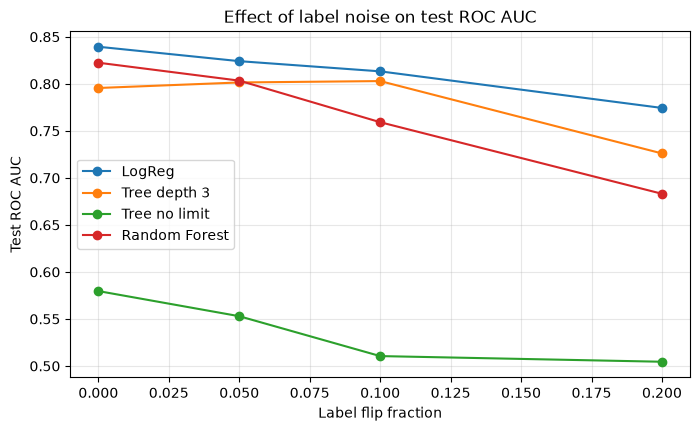

In [12]:
# YOUR CODE HERE
def flip_labels(y, frac, rng):
    y = np.array(y, copy=True)
    n = int(round(frac * len(y)))
    idx = rng.choice(len(y), n, replace=False)
    y[idx] = 1 - y[idx]
    return y

def make_models():
    return {"LogReg": make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000, random_state=SEED)),
            "Tree depth 3": DecisionTreeClassifier(max_depth=3, random_state=SEED),
            "Tree no limit": DecisionTreeClassifier(random_state=SEED),
            "Random Forest": RandomForestClassifier(n_estimators=200, min_samples_leaf=5, random_state=SEED, n_jobs=-1)}

def test_auc(model, Xtr, ytr):
    return roc_auc_score(y_test, model.fit(Xtr, ytr).predict_proba(X_test)[:, 1])

fracs = [0, 0.05, 0.10, 0.20]
res = {}
for f in fracs:
    reps = 1 if f == 0 else 5
    scores = {k: [] for k in make_models()}
    for r in range(reps):
        rng = np.random.default_rng(SEED + r)
        yn = flip_labels(y_train, f, rng) if f > 0 else y_train.values
        for k, m in make_models().items():
            scores[k].append(test_auc(m, X_train, yn))
    res[f] = {k: np.mean(v) for k, v in scores.items()}
label_noise = pd.DataFrame(res).T
label_noise.index.name = "Label flip fraction"
print(label_noise.round(4).to_string())

label_noise.plot(marker="o", figsize=(8, 4.5))
plt.ylabel("Test ROC AUC"); plt.title("Effect of label noise on test ROC AUC"); plt.grid(alpha=0.3); plt.show()


### Task 5.2 — Feature noise
Add Gaussian noise to the **train** values of `age`, `avg_glucose_level` and `bmi`: `noise = random normal × (column std) × level`. Levels 0, 0.5, 1, 2; five repeats; test set untouched. Same kind of table and plot. (If you scale for Logistic Regression, fit the scaler on the noisy training data.)

                     LogReg  Tree depth 3  Tree no limit  Random Forest
Noise level (x std)                                                    
0.0                  0.8394        0.7956         0.5797         0.8224
0.5                  0.8337        0.7995         0.5608         0.8140
1.0                  0.8098        0.7610         0.5283         0.7870
2.0                  0.7695        0.6942         0.5309         0.7406


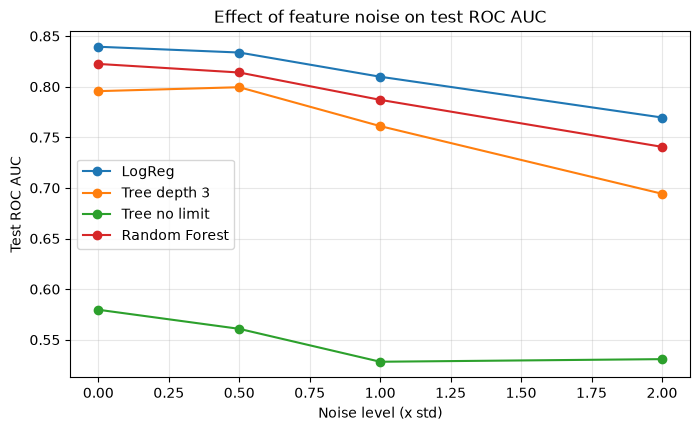

In [13]:
# YOUR CODE HERE
noisy_cols = ["age", "avg_glucose_level", "bmi"]
levels = [0, 0.5, 1, 2]
res = {}
for lv in levels:
    reps = 1 if lv == 0 else 5
    scores = {k: [] for k in make_models()}
    for r in range(reps):
        rng = np.random.default_rng(SEED + r)
        Xn = X_train.copy()
        for c in noisy_cols:
            Xn[c] = Xn[c] + rng.normal(size=len(Xn)) * X_train[c].std() * lv
        for k, m in make_models().items():          # LogReg pipeline refits the scaler on the noisy train data
            scores[k].append(test_auc(m, Xn, y_train))
    res[lv] = {k: np.mean(v) for k, v in scores.items()}
feat_noise = pd.DataFrame(res).T
feat_noise.index.name = "Noise level (x std)"
print(feat_noise.round(4).to_string())

feat_noise.plot(marker="o", figsize=(8, 4.5))
plt.ylabel("Test ROC AUC"); plt.title("Effect of feature noise on test ROC AUC"); plt.grid(alpha=0.3); plt.show()


### Task 5.3 — SMOTE and noisy labels
Flip 10% of the training labels (3 different random draws). For Logistic Regression and Random Forest compare **PR AUC and ROC AUC with and without SMOTE** (SMOTE applied after the noise is added).

In [14]:
# YOUR CODE HERE
rows = []
for model_name, mk, use_scaled in [("LogReg", mk_lr, True), ("RandomForest", mk_rf, False)]:
    Xtr_base, Xte_base = (Xs_train, Xs_test) if use_scaled else (X_train, X_test)
    for with_smote in [False, True]:
        pr, ro = [], []
        for r in range(3):
            rng = np.random.default_rng(100 + r)
            yn = flip_labels(y_train, 0.10, rng)
            Xr, yr = Xtr_base, yn
            if with_smote:
                Xr, yr = SMOTE(random_state=SEED).fit_resample(Xtr_base, yn)   # SMOTE after noise
            m = mk().fit(Xr, yr)
            p = m.predict_proba(Xte_base)[:, 1]
            pr.append(average_precision_score(y_test, p)); ro.append(roc_auc_score(y_test, p))
        rows.append({"Model": model_name, "SMOTE": "with" if with_smote else "without",
                     "PR AUC": np.mean(pr), "ROC AUC": np.mean(ro)})
print(pd.DataFrame(rows).round(4).to_string(index=False))


       Model   SMOTE  PR AUC  ROC AUC
      LogReg without  0.2295   0.8224
      LogReg    with  0.2450   0.8199
RandomForest without  0.1709   0.7690
RandomForest    with  0.0654   0.6211


**Question 5.1:** Which model is most damaged by noise and which is most stable? Quote numbers at the highest noise level and explain using what you learned in Part 2.

**Question 5.2:** Which hurts more here — label noise or feature noise of a comparable level? Give a short reason.

**Question 5.3:** What did SMOTE do to each model when the labels were noisy? Explain why SMOTE can amplify label noise.

**Your answer:**
**5.1:** At 20% label noise Random Forest is damaged most (AUC 0.822 to 0.683). Logistic Regression is the most stable (0.839 to 0.774). Flexible models like forests and deep trees (Part 2: high variance) learn the wrong labels, while simple models average the noise out.

**5.2:** Label noise hurts more. At 20% label noise Random Forest falls to 0.683, but at the highest feature noise it only falls to 0.741. Wrong labels teach the model wrong answers, while noisy features only blur the inputs.

**5.3:** With noisy labels SMOTE changed Logistic Regression very little (PR AUC 0.2295 to 0.2450), but it hurt Random Forest (PR AUC 0.1709 to 0.0654). SMOTE copies the minority rows, and many of them are wrong labels after the noise, so it multiplies the noise.




---

## Part 6 — Final Decision and Conclusion
1. Choose your final approach for the hospital (model + rebalancing method or threshold). Build a final table on the test set comparing the default threshold 0.5 with your choice: Precision, Recall, F1, number of false alarms and number of missed strokes.
2. Write an **Executive Summary** (6–8 lines): what you chose, its recall and precision with numbers, the price paid, how you avoided leakage, and one limitation (think about only 50 stroke patients in the test set, and about how the threshold was chosen).

In [15]:
# YOUR CODE HERE
rows = []
for name, thr_use in [("Default threshold 0.5", 0.5), ("Chosen threshold %.3f" % threshold, threshold)]:
    pred = (p_test >= thr_use).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_test, pred).ravel()
    rows.append({"Setting": name, "Precision": precision_score(y_test, pred, zero_division=0),
                 "Recall": recall_score(y_test, pred), "F1": f1_score(y_test, pred, zero_division=0),
                 "False alarms": fp, "Missed strokes": fn, "Flagged": int(pred.sum())})
final = pd.DataFrame(rows)
print(final.round(3).to_string(index=False))

               Setting  Precision  Recall    F1  False alarms  Missed strokes  Flagged
 Default threshold 0.5      1.000    0.02 0.039             0              49        1
Chosen threshold 0.051      0.135    0.82 0.232           262               9      303


**Executive Summary**

I chose Logistic Regression with a lower decision threshold of 0.051. The threshold was chosen on out-of-fold predictions of the training data only. On the test set it catches 41 of 50 strokes (recall 0.82) with precision 0.135, while the default threshold 0.5 catches only 1 of 50 (recall 0.02). The price is 262 false alarms and 9 missed strokes. I avoided leakage by learning the median, the scaler and the threshold from the training data only, and by never resampling the test set. One limitation: the test set has only 50 stroke patients, so one patient changes recall by 2 points and the result is uncertain, and the threshold was learned from only 199 training strokes.



**Final Reflection:** (a) What was the most surprising result in this lab? (b) If you had one more hour, what would you try next?

**Your answer:**

**(a)** A model with 95% accuracy found only 1 stroke out of 50.

**(b)** I would test the model on more splits to see how stable the results are.


